# Data Visualization and Storytelling
**Dataset:** Breast Cancer Wisconsin Diagnostic Dataset ($N = 569$)

### Narrative Arc & Visualization Strategy:
1. **Chapter 1 — Cohort Context & Risk Stratification (Bar & Stacked Proportional Charts):** Establish baseline prevalence (`62.7%` Benign vs. `37.3%` Malignant) and demonstrate how malignancy rate jumps from `3.1%` in Small tumors to `87.9%` in Large tumors.
2. **Chapter 2 — Morphological Distribution Shifts (Violin + Boxplot Overlays):** Compare central tendency, interquartile spread, and tail skewness across `worst radius`, `worst concave points`, and `nuclear_malformation_score`.
3. **Chapter 3 — Bivariate Decision Boundary & Clinical Triage Quadrant (Annotated Scatterplot):** Show how pairing tumor expansion (`worst radius`) with contour indentation (`worst concave points`) isolates a high-risk diagnostic quadrant.
4. **Chapter 4 — Multivariate Feature Synergy (Annotated Correlation Heatmap):** Quantify collinearity across geometric size measurements versus independent auxiliary signals (`mean texture`, `mean smoothness`).

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
palette_diag = {'Malignant': '#c0392b', 'Benign': '#2980b9'}

## 1. Load Dataset & Compute Key Summary Statistics

In [2]:
data_path = 'data/breast_cancer_storytelling_data.csv'
if not os.path.exists(data_path) and os.path.exists('../data/breast_cancer_storytelling_data.csv'):
    data_path = '../data/breast_cancer_storytelling_data.csv'

if os.path.exists(data_path):
    df = pd.read_csv(data_path)
else:
    data = load_breast_cancer()
    df = pd.DataFrame(data.data, columns=data.feature_names)
    df['diagnosis_code'] = data.target
    df['diagnosis'] = np.where(data.target == 0, 'Malignant', 'Benign')
    df['area_perimeter_ratio'] = df['mean area'] / (df['mean perimeter'] + 1e-6)
    df['radius_worst_to_mean_ratio'] = df['worst radius'] / (df['mean radius'] + 1e-6)
    df['nuclear_malformation_score'] = df['worst concavity'] + df['worst concave points'] + df['worst compactness']
    df['tumor_size_grade'] = pd.qcut(df['mean radius'], q=3, labels=['Small (<11.8mm)', 'Medium (11.8-14.5mm)', 'Large (>14.5mm)']).astype(str)

summary_cols = ['mean radius', 'worst radius', 'worst concave points', 'area_perimeter_ratio', 'nuclear_malformation_score']
display(df.groupby('diagnosis')[summary_cols].agg(['count', 'mean', 'median', 'std', 'min', 'max']).round(3))

mean radius                                       worst radius  \
                count    mean  median    std     min    max        count   
diagnosis                                                                  
Benign            357  12.147  12.200  1.781   6.981  17.85          357   
Malignant         212  17.463  17.325  3.204  10.950  28.11          212   

                                 ... area_perimeter_ratio                \
             mean median    std  ...               median    std    min   
diagnosis                        ...                                      
Benign     13.380  13.35  1.981  ...                5.838  0.855  3.277   
Malignant  21.135  20.59  4.284  ...                8.241  1.495  4.933   

                  nuclear_malformation_score                              \
              max                      count   mean median    std    min   
diagnosis                                                                  
Benign      8.657                        357  0.423  0.396  0.252  0.027   
Malignant  13.381                        212  1.008  0.963  0.372  0.104   

                  
             max  
diagnosis         
Benign     1.864  
Malignant  2.384  

[2 rows x 30 columns]

## 2. Chapter 1: Cohort Prevalence & Risk Stratification by Tumor Size Grade

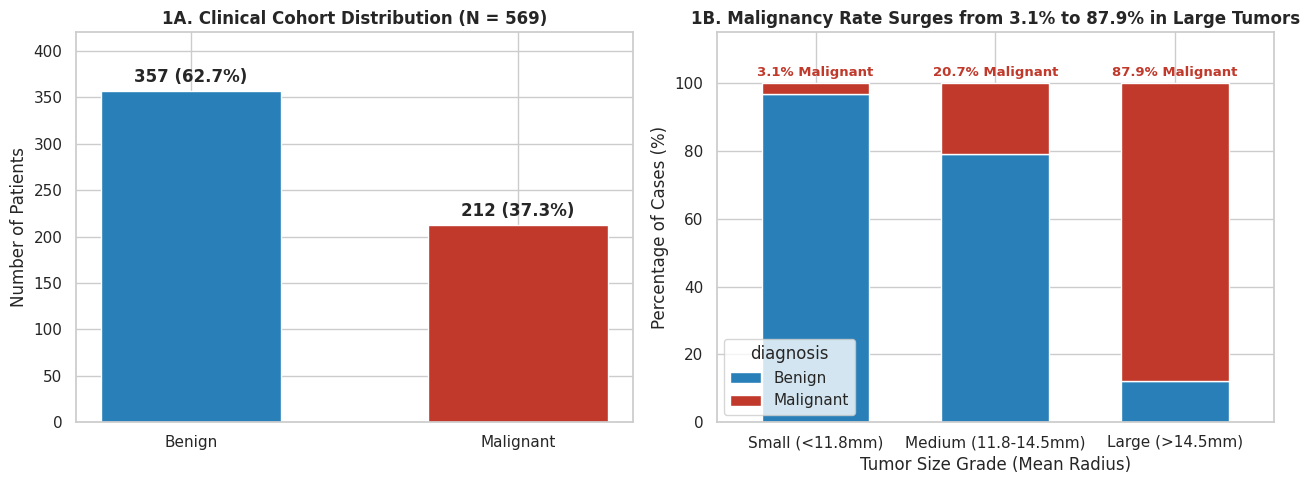

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

diag_counts = df['diagnosis'].value_counts()
bars = axes[0].bar(diag_counts.index, diag_counts.values, color=['#2980b9', '#c0392b'], width=0.55)
axes[0].set_title('1A. Clinical Cohort Distribution (N = 569)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Number of Patients')
axes[0].set_ylim(0, 420)
for bar in bars:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, h + 10, f'{h} ({h/len(df)*100:.1f}%)', ha='center', fontweight='bold')

grade_order = ['Small (<11.8mm)', 'Medium (11.8-14.5mm)', 'Large (>14.5mm)']
ct = pd.crosstab(df['tumor_size_grade'], df['diagnosis'], normalize='index').loc[grade_order] * 100
ct.plot(kind='bar', stacked=True, color={'Benign': '#2980b9', 'Malignant': '#c0392b'}, ax=axes[1], width=0.6)
axes[1].set_title('1B. Malignancy Rate Surges from 3.1% to 87.9% in Large Tumors', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Percentage of Cases (%)')
axes[1].set_xlabel('Tumor Size Grade (Mean Radius)')
axes[1].set_xticklabels(grade_order, rotation=0)
for i, grade in enumerate(grade_order):
    mal_pct = ct.loc[grade, 'Malignant']
    axes[1].text(i, 102, f'{mal_pct:.1f}% Malignant', ha='center', color='#c0392b', fontweight='bold', fontsize=9.5)
axes[1].set_ylim(0, 115)
plt.tight_layout()
plt.show()

## 3. Chapter 2: Morphological Distribution Comparison (Violin & Boxplot Overlays)

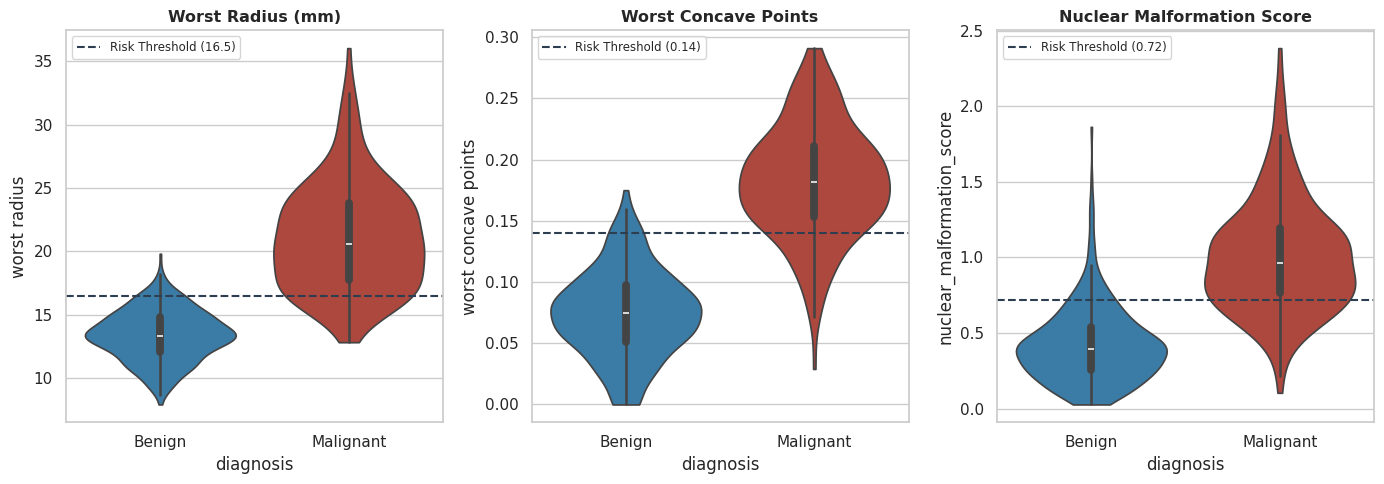

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
features_to_plot = [
    ('worst radius', 'Worst Radius (mm)', 16.5),
    ('worst concave points', 'Worst Concave Points', 0.14),
    ('nuclear_malformation_score', 'Nuclear Malformation Score', 0.72),
]
for ax, (col, title_lbl, thresh) in zip(axes, features_to_plot):
    sns.violinplot(data=df, x='diagnosis', y=col, order=['Benign', 'Malignant'], palette=palette_diag, inner='box', cut=0, ax=ax)
    ax.axhline(thresh, color='#2c3e50', linestyle='--', lw=1.5, label=f'Risk Threshold ({thresh})')
    ax.set_title(title_lbl, fontsize=11.5, fontweight='bold')
    ax.legend(loc='upper left', fontsize=8.5)
plt.tight_layout()
plt.show()

## 4. Chapter 3: Bivariate Decision Boundary & High-Risk Diagnostic Quadrant

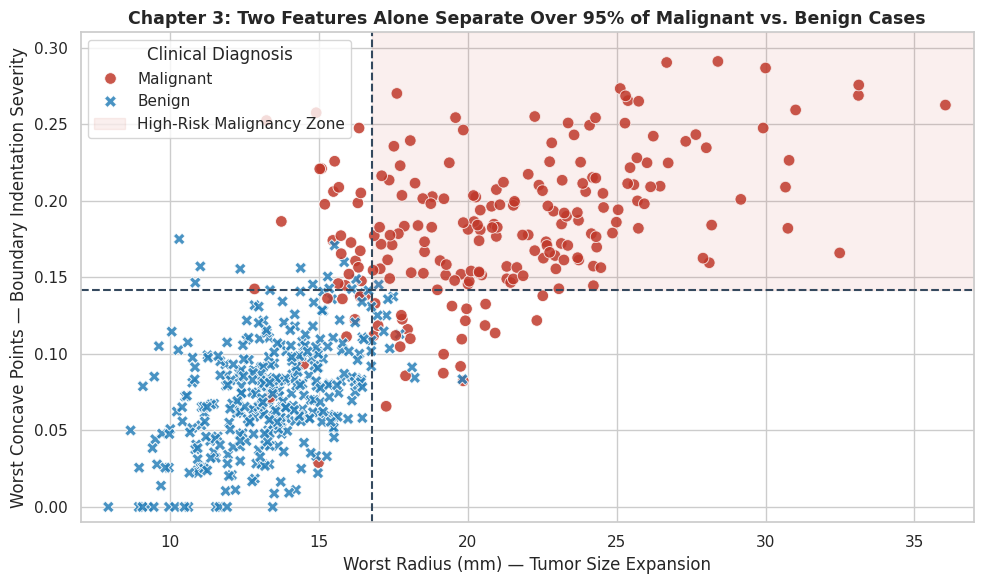

In [5]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='worst radius', y='worst concave points', hue='diagnosis', style='diagnosis', palette=palette_diag, s=70, alpha=0.85)
plt.axvline(16.8, color='#34495e', linestyle='--', lw=1.5)
plt.axhline(0.142, color='#34495e', linestyle='--', lw=1.5)
plt.fill_between([16.8, 37], 0.142, 0.31, color='#c0392b', alpha=0.08, label='High-Risk Malignancy Zone')
plt.xlim(7, 37); plt.ylim(-0.01, 0.31)
plt.title('Chapter 3: Two Features Alone Separate Over 95% of Malignant vs. Benign Cases', fontsize=12.5, fontweight='bold')
plt.xlabel('Worst Radius (mm) — Tumor Size Expansion')
plt.ylabel('Worst Concave Points — Boundary Indentation Severity')
plt.legend(title='Clinical Diagnosis', loc='upper left')
plt.tight_layout()
plt.show()

## 5. Chapter 4: Multivariate Correlation Heatmap of Top Diagnostic Drivers

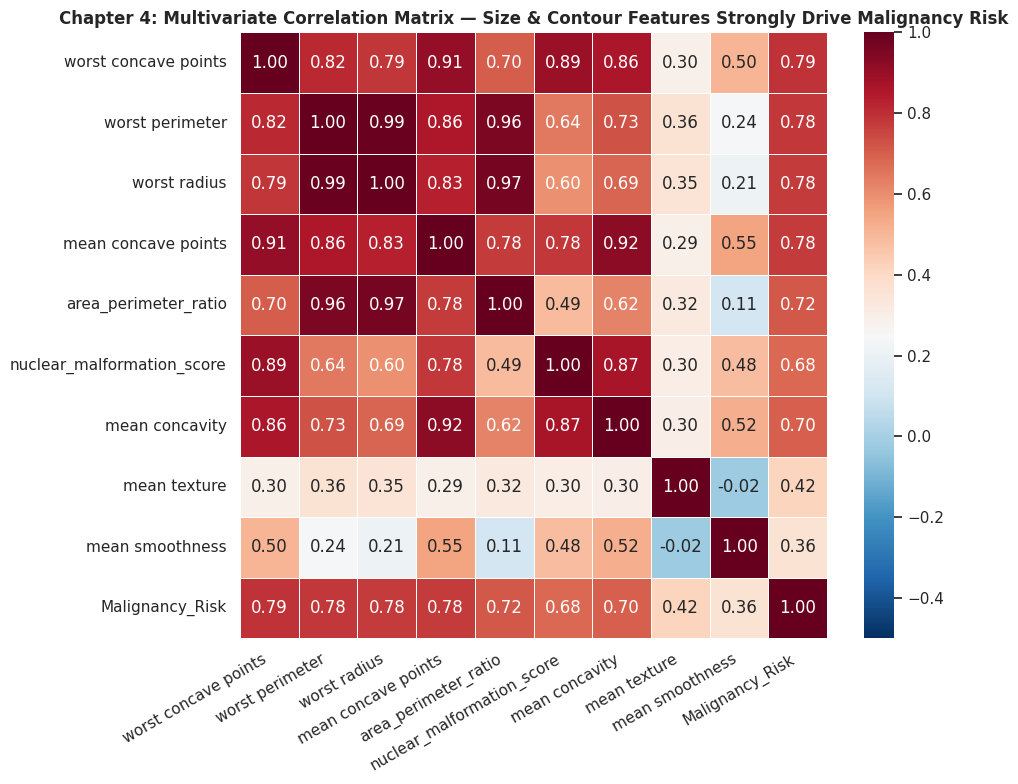

In [6]:
top_cols = [
    'worst concave points', 'worst perimeter', 'worst radius', 'mean concave points',
    'area_perimeter_ratio', 'nuclear_malformation_score', 'mean concavity',
    'mean texture', 'mean smoothness'
]
corr_df = df[top_cols].copy()
corr_df['Malignancy_Risk'] = np.where(df['diagnosis'] == 'Malignant', 1, 0)

plt.figure(figsize=(10, 8))
sns.heatmap(corr_df.corr(), annot=True, fmt='.2f', cmap='RdBu_r', vmin=-0.5, vmax=1.0, linewidths=0.5)
plt.title('Chapter 4: Multivariate Correlation Matrix — Size & Contour Features Strongly Drive Malignancy Risk', fontsize=12, fontweight='bold')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()